<a href="https://colab.research.google.com/github/meWasim/BookStack/blob/development/ML_project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from pandas.core.groupby import DataFrameGroupBy
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings


warnings.filterwarnings('ignore')
df = pd.read_csv('/content/insurance.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


EDA

In [3]:
df.shape


(1338, 7)

In [4]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [6]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [8]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

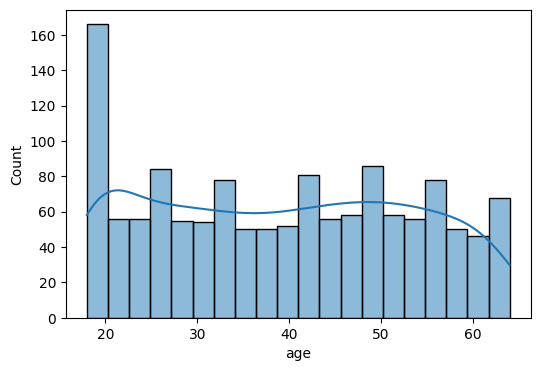

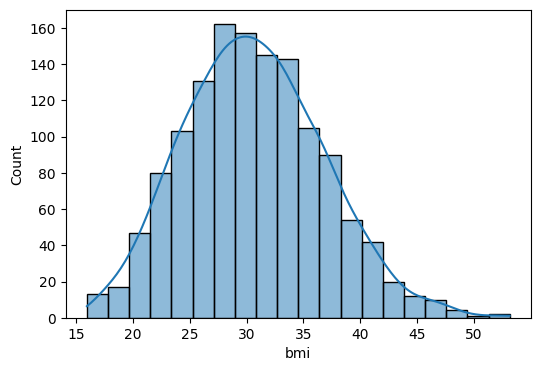

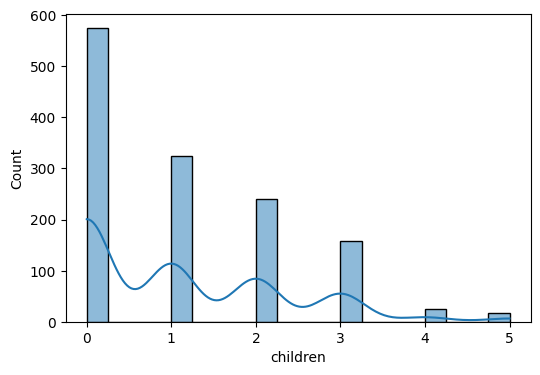

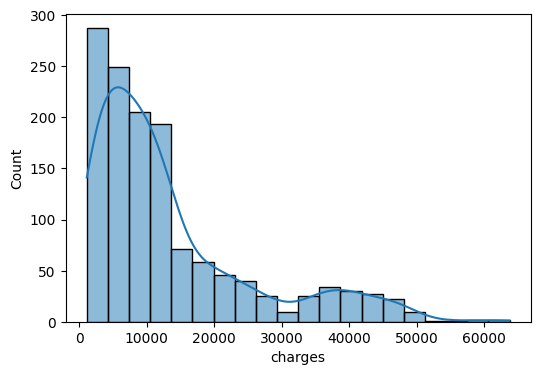

In [9]:

# Restore pd.DataFrame to its correct constructor class
pd.DataFrame = pd.core.frame.DataFrame

# Exclude 'region' from numeric_columns since it is a categorical string column
numeric_columns = ['age', 'bmi', 'children','charges']

for col in numeric_columns:
  plt.figure(figsize=(6,4))
  sns.histplot(df[col], kde=True, bins=20)
  # plt.title(f'Distribution of {col}')
  # plt.show()

<Axes: xlabel='children', ylabel='count'>

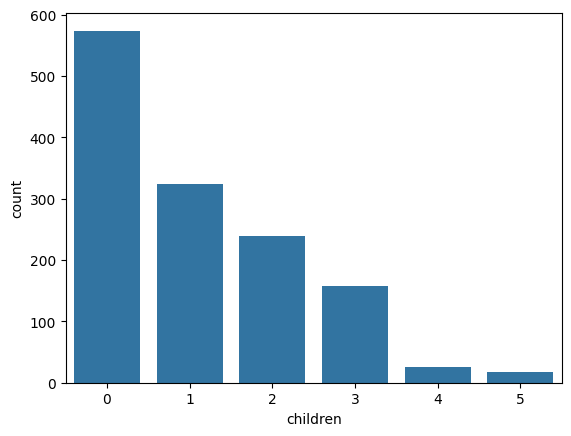

In [10]:
sns.countplot( x=df['children'])

<Axes: xlabel='sex', ylabel='count'>

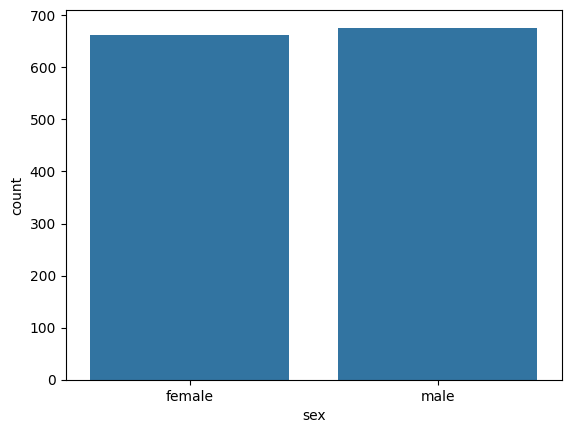

In [11]:
sns.countplot(x=df['sex'])

<Axes: xlabel='smoker', ylabel='count'>

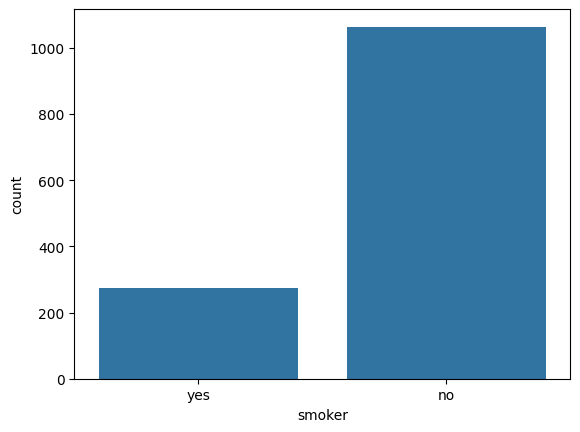

In [12]:
sns.countplot(x=df['smoker'])

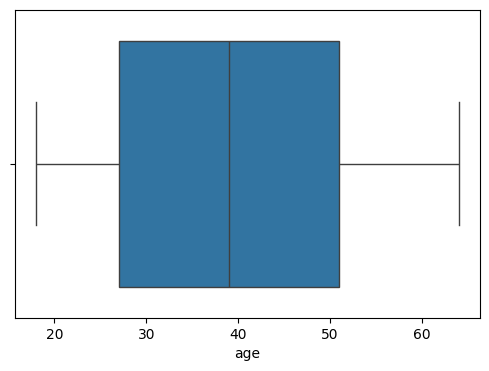

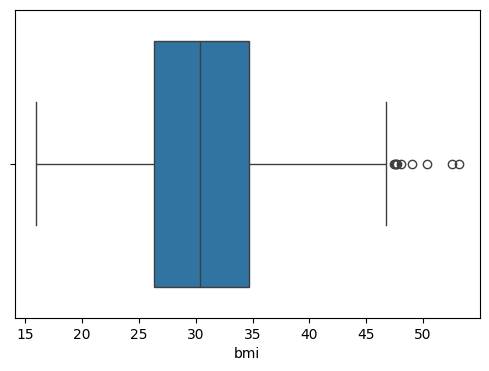

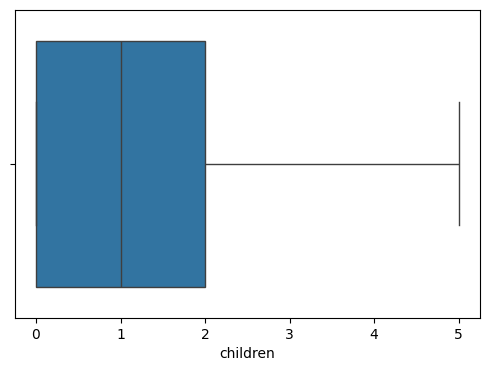

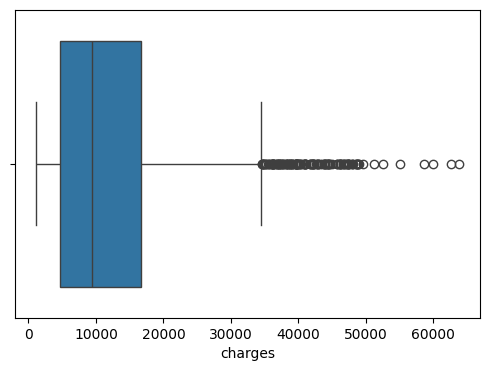

In [13]:
for col in numeric_columns:
  plt.figure(figsize=(6,4))
  sns.boxplot(x=df[col])

<Axes: >

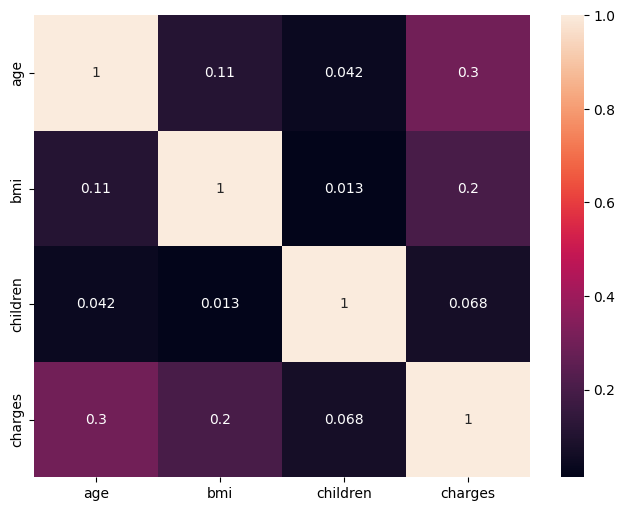

In [14]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)

Data Cleaning and preprocessing

In [15]:
df_cleaned=df.copy()
df_cleaned

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [16]:
df_cleaned.shape

(1338, 7)

In [17]:
df_cleaned.drop_duplicates(inplace=True)

In [18]:
df_cleaned.shape

(1337, 7)

In [19]:
df_cleaned.dtypes

,0
age,int64
sex,object
bmi,float64
children,int64
smoker,object
region,object
charges,float64


In [20]:
df_cleaned['sex'].value_counts()

,count
sex,
male,675
female,662


In [21]:
df_cleaned['sex']=df_cleaned['sex'].map({'male':0,'female':1})

In [22]:
df_cleaned

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,no,northwest,10600.54830
1334,18,1,31.920,0,no,northeast,2205.98080
1335,18,1,36.850,0,no,southeast,1629.83350
1336,21,1,25.800,0,no,southwest,2007.94500


In [23]:
df_cleaned['smoker'].value_counts()

,count
smoker,
no,1063
yes,274


In [24]:
df_cleaned['smoker']=df_cleaned['smoker'].map({'no':0,'yes':1})

In [25]:
df_cleaned


,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,northwest,10600.54830
1334,18,1,31.920,0,0,northeast,2205.98080
1335,18,1,36.850,0,0,southeast,1629.83350
1336,21,1,25.800,0,0,southwest,2007.94500


In [26]:
df_cleaned.rename(columns={
    'sex':'is_female',
    'smoker':'is_smoker'
},inplace=True)

In [27]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [28]:
df_cleaned['region'].value_counts()

,count
region,
southeast,364
southwest,325
northwest,324
northeast,324


In [29]:
df_cleaned = pd.get_dummies(df_cleaned,columns = ['region'],drop_first=False)

In [30]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,False,False,True
1,18,0,33.770,1,0,1725.55230,False,False,True,False
2,28,0,33.000,3,0,4449.46200,False,False,True,False
3,33,0,22.705,0,0,21984.47061,False,True,False,False
4,32,0,28.880,0,0,3866.85520,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,10600.54830,False,True,False,False
1334,18,1,31.920,0,0,2205.98080,True,False,False,False
1335,18,1,36.850,0,0,1629.83350,False,False,True,False
1336,21,1,25.800,0,0,2007.94500,False,False,False,True


In [31]:
df_cleaned= df_cleaned.astype(int)

In [32]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,0,0,1
1,18,0,33,1,0,1725,0,0,1,0
2,28,0,33,3,0,4449,0,0,1,0
3,33,0,22,0,0,21984,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0
1334,18,1,31,0,0,2205,1,0,0,0
1335,18,1,36,0,0,1629,0,0,1,0
1336,21,1,25,0,0,2007,0,0,0,1


<Axes: >

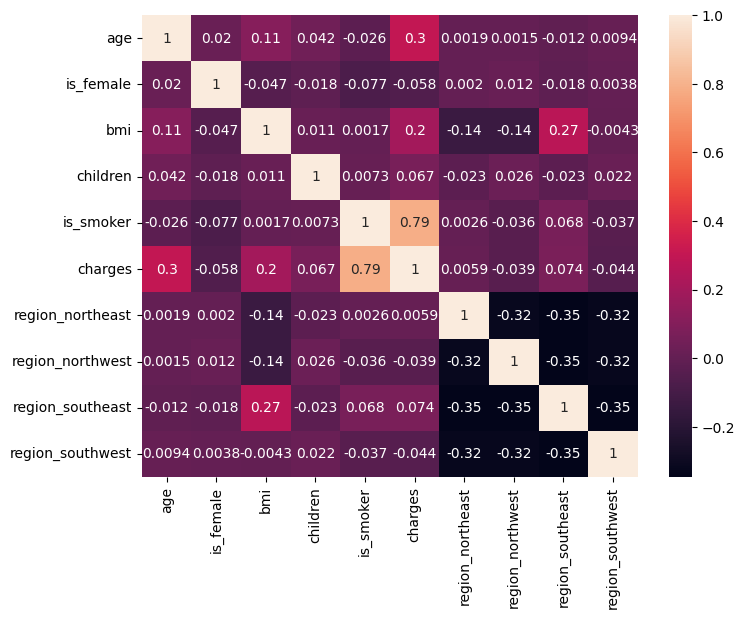

In [33]:
plt.figure(figsize=(8,6))
sns.heatmap(df_cleaned.corr(numeric_only=True),annot=True)

Feature Engineering

<Axes: xlabel='bmi', ylabel='Count'>

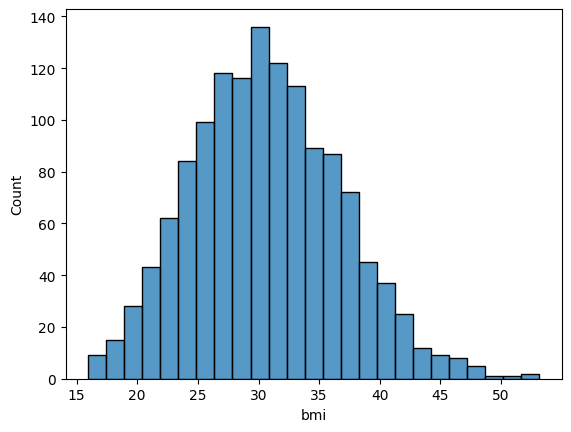

In [34]:
sns.histplot(df['bmi'])

In [35]:
df_cleaned['bmi_category']=pd.cut(
    df_cleaned['bmi'],
    bins=[0,18.5,24.9,29.9 ,float('inf')],
    labels=['Underweight','Normal','Overweight','Obese']

)

In [36]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27,0,1,16884,0,0,0,1,Overweight
1,18,0,33,1,0,1725,0,0,1,0,Obese
2,28,0,33,3,0,4449,0,0,1,0,Obese
3,33,0,22,0,0,21984,0,1,0,0,Normal
4,32,0,28,0,0,3866,0,1,0,0,Overweight
...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0,Obese
1334,18,1,31,0,0,2205,1,0,0,0,Obese
1335,18,1,36,0,0,1629,0,0,1,0,Obese
1336,21,1,25,0,0,2007,0,0,0,1,Overweight


In [37]:
df_cleaned = pd.get_dummies(df_cleaned,columns=['bmi_category'],drop_first=False)


In [38]:
df_cleaned=df_cleaned.astype(int)

In [39]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27,0,1,16884,0,0,0,1,0,0,1,0
1,18,0,33,1,0,1725,0,0,1,0,0,0,0,1
2,28,0,33,3,0,4449,0,0,1,0,0,0,0,1
3,33,0,22,0,0,21984,0,1,0,0,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0,0,0,0,1
1334,18,1,31,0,0,2205,1,0,0,0,0,0,0,1
1335,18,1,36,0,0,1629,0,0,1,0,0,0,0,1
1336,21,1,25,0,0,2007,0,0,0,1,0,0,1,0


<Axes: >

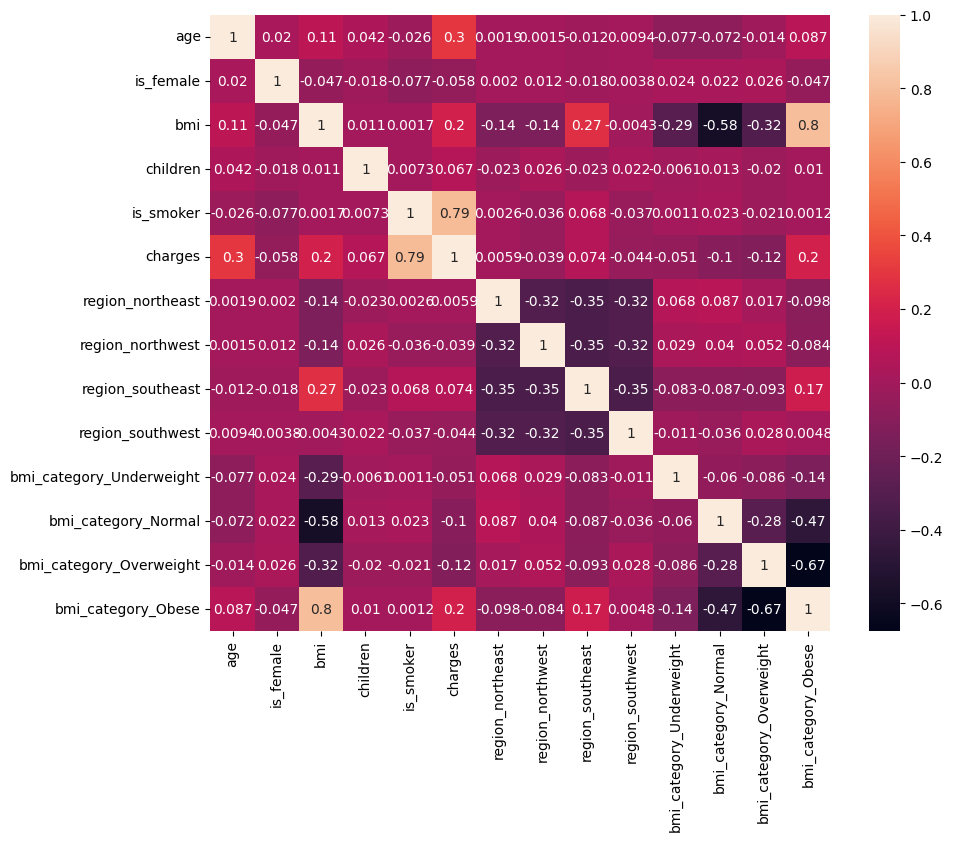

In [40]:
plt.figure(figsize=(10,8))
sns.heatmap(df_cleaned.corr(numeric_only=True),annot=True)

In [41]:
df_cleaned.describe()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
count,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,0.495138,30.169783,1.095737,0.204936,13278.628272,0.242334,0.242334,0.272251,0.243082,0.017951,0.165295,0.288706,0.528048
std,14.044333,0.500163,6.122163,1.205571,0.403806,12110.361125,0.428655,0.428655,0.445285,0.429104,0.132822,0.371586,0.453331,0.499399
min,18.000000,0.000000,15.000000,0.000000,0.000000,1121.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,0.000000,26.000000,0.000000,0.000000,4746.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,39.000000,0.000000,30.000000,1.000000,0.000000,9386.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,51.000000,1.000000,34.000000,2.000000,0.000000,16657.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000
max,64.000000,1.000000,53.000000,5.000000,1.000000,63770.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [42]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   age                       1337 non-null   int64
 1   is_female                 1337 non-null   int64
 2   bmi                       1337 non-null   int64
 3   children                  1337 non-null   int64
 4   is_smoker                 1337 non-null   int64
 5   charges                   1337 non-null   int64
 6   region_northeast          1337 non-null   int64
 7   region_northwest          1337 non-null   int64
 8   region_southeast          1337 non-null   int64
 9   region_southwest          1337 non-null   int64
 10  bmi_category_Underweight  1337 non-null   int64
 11  bmi_category_Normal       1337 non-null   int64
 12  bmi_category_Overweight   1337 non-null   int64
 13  bmi_category_Obese        1337 non-null   int64
dtypes: int64(14)
memory usage: 156.7 KB


In [43]:
df_cleaned.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
       'bmi_category_Overweight', 'bmi_category_Obese'],
      dtype='object')

In [44]:
from sklearn.preprocessing import StandardScaler
cols = ['age', 'bmi', 'children']
scalar = StandardScaler()
df_cleaned[cols] = scalar.fit_transform(df_cleaned[cols])

In [45]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,0,1,0,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725,0,0,1,0,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,4449,0,0,1,0,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,1,0,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,1,0,0,0,0,1,0


In [53]:
from scipy.stats import pearsonr
#calculate correlation claculation

selected_features=['age', 'is_female', 'bmi', 'children', 'is_smoker', '',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
       'bmi_category_Overweight', 'bmi_category_Obese']
correlations={
    feature:pearsonr(df_cleaned[feature],df_cleaned['charges'])[0]
    for feature in selected_features
}
correlation_df= pd.DataFrame(list(correlations.items()),columns=['Feature','Pearson Correlation'])
correlation_df.sort_values(by='Pearson Correlation',ascending= False)

,Feature,Pearson Correlation
4,is_smoker,0.787234
0,age,0.298309
12,bmi_category_Obese,0.200348
2,bmi,0.196236
7,region_southeast,0.073577
3,children,0.067390
5,region_northeast,0.005946
6,region_northwest,-0.038695
8,region_southwest,-0.043637
9,bmi_category_Underweight,-0.050599


In [61]:
import pandas as pd
from scipy.stats import chi2_contingency
from IPython.display import display

cat_features = [
    'is_female', 'is_smoker',
    'region_northeast', 'region_northwest',
    'region_southeast', 'region_southwest',
    'bmi_category_Underweight', 'bmi_category_Normal',
    'bmi_category_Overweight', 'bmi_category_Obese'
]

alpha = 0.05

# Divide charges into 4 quartiles
df_cleaned['charges_bin'] = pd.qcut(
    df_cleaned['charges'],
    q=4,
    labels=False
)

chi2_results = {}

for col in cat_features:
    # Create contingency table
    contingency = pd.crosstab(
        df_cleaned[col],
        df_cleaned['charges_bin']
    )

    # Apply Chi-square test
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)

    decision = (
        'Reject Null (Keep Feature)'
        if p_val < alpha
        else 'Fail to Reject Null (Consider Dropping)'
    )

    chi2_results[col] = {
        'chi2_statistic': chi2_stat,
        'p_value': p_val,
        'Decision': decision
    }

# Create and sort results DataFrame
chi2_df = pd.DataFrame(chi2_results).T
chi2_df = chi2_df.sort_values(by='p_value')

# Print results
display(
    chi2_df.style
    .format({
        'chi2_statistic': '{:.4f}',
        'p_value': '{:.6f}'
    })
    .background_gradient(subset=['p_value'], cmap='RdYlGn_r')
)

,chi2_statistic,p_value,Decision
is_smoker,848.2192,0.000000,Reject Null (Keep Feature)
region_southeast,15.9982,0.001135,Reject Null (Keep Feature)
is_female,10.2588,0.016490,Reject Null (Keep Feature)
bmi_category_Obese,8.5157,0.036473,Reject Null (Keep Feature)
region_northeast,6.4384,0.092122,Fail to Reject Null (Consider Dropping)
region_southwest,5.0919,0.165191,Fail to Reject Null (Consider Dropping)
bmi_category_Overweight,4.2515,0.235557,Fail to Reject Null (Consider Dropping)
bmi_category_Normal,3.7081,0.294760,Fail to Reject Null (Consider Dropping)
bmi_category_Underweight,3.3740,0.337471,Fail to Reject Null (Consider Dropping)
region_northwest,1.1342,0.768815,Fail to Reject Null (Consider Dropping)


In [63]:
final_df = df_cleaned[['age', 'is_smoker', 'children', 'bmi', 'charges', 'region_southeast', 'is_female', 'bmi_category_Obese']]

In [64]:
final_df

,age,is_smoker,children,bmi,charges,region_southeast,is_female,bmi_category_Obese
0,-1.440418,1,-0.909234,-0.517949,16884,0,1,0
1,-1.511647,0,-0.079442,0.462463,1725,1,0,1
2,-0.799350,0,1.580143,0.462463,4449,1,0,1
3,-0.443201,0,-0.909234,-1.334960,21984,0,0,0
4,-0.514431,0,-0.909234,-0.354547,3866,0,0,0
...,...,...,...,...,...,...,...,...
1333,0.767704,0,1.580143,-0.027743,10600,0,0,1
1334,-1.511647,0,-0.909234,0.135659,2205,0,1,1
1335,-1.511647,0,-0.909234,0.952670,1629,1,1,1
1336,-1.297958,0,-0.909234,-0.844753,2007,0,1,0
